##**Análisis de resultados – Optimización bayesiana de LightGBM**

Comparación de las ganancias obtenidas en Kaggle para los experimentos A (5 HP), B (11 HP) y C (14 HP), utilizando 10 semillas por experimento.

Se realizará un análisis descriptivo de las ganancias y se compararán los resultados de los experimentos mediante el test de Wilcoxon para muestras apareadas. Además, se aplicará la corrección de Holm a los valores p, ya que se realizarán varias comparaciones.

###Paso 1: Ganancias de los experimentos

Lo primero que se reliza son vectores de las ganancias maximas obtenidas en los 3 experimentos con las 10 semillas. 

In [16]:
# ==========================================================
# 1. GANANCIAS DE LOS EXPERIMENTOS
# ==========================================================

# Experimento A: 5 hiperparámetros

ganancia_A <- c(
  85732, 90135, 87310, 86313, 90550,
  87809, 97944, 88224, 92876, 85566
)

# Experimento B: 11 hiperparámetros

ganancia_B <- c(
  92959,89304,89885,87476,80664,
   87809, 91547, 91713, 87975, 85732
 )

# Experimento C: 14 hiperparámetros

ganancia_C <- c(
  88390, 87642, 86313, 84818, 81412,
  81329, 84486,  90799, 82243, 83738
)

###Paso 2: Tabla de resultados

Lo siguiente que se hace es crear una tabla con los vectores creados en el paso anterior

In [17]:
# ==========================================================
# 2. TABLA DE RESULTADOS
# ==========================================================

ganancias <- data.frame(
  Semilla = c(
  163741, 195401, 751643, 959473, 983327,
  193357, 826351, 143249, 648931, 268693
),
  A = ganancia_A,
  B = ganancia_B,
  C = ganancia_C
)

print(ganancias)

# Cantidad de resultados disponibles por experimento

colSums(!is.na(ganancias[, c("A", "B", "C")]))

   Semilla     A     B     C
1   163741 85732 92959 88390
2   195401 90135 89304 87642
3   751643 87310 89885 86313
4   959473 86313 87476 84818
5   983327 90550 80664 81412
6   193357 87809 87809 81329
7   826351 97944 91547 84486
8   143249 88224 91713 90799
9   648931 92876 87975 82243
10  268693 85566 85732 83738


A  B  C 
10 10 10

###Paso 3: Cantidad de clientes enviados a Kaggle

Para complementar el análisis de las ganancias, también se consideró la cantidad de clientes seleccionados con la que se obtuvo la ganancia máxima en Kaggle. Al igual que con las ganancias, se generaron tres vectores con 10 resultados cada uno, que luego se incorporaron a la tabla de ganancias.

In [18]:
# ==========================================================
# 3. CANTIDAD DE CLIENTES EN LA GANANCIA MAXIMA
# ==========================================================

clientes_A <- c(
  2000, 1900, 1800, 1600, 1500,
  2000, 1900, 2400, 2000, 2100
)

clientes_B <- c(
  2400, 2100, 2100, 2500, 1900,
  2300, 1900, 2300, 1900, 2400
)

clientes_C <- c(
  1500, 2300, 1300, 2500, 1900,
  2400, 2300, 1900, 2400, 1900
)

# Incorporo esta información a la tabla existente

ganancias$Clientes_A <- clientes_A
ganancias$Clientes_B <- clientes_B
ganancias$Clientes_C <- clientes_C

###Paso 4: Mejores AUC de validación

Para complementar el análisis de las ganancias, también se consideró la AUC de validación obtenida luego de la optimización bayesiana. Al igual que con las ganancias, se generaron tres vectores con 10 resultados cada uno, que luego se incorporaron a la tabla de ganancias.

In [19]:
# ==========================================================
# 4. MEJORES AUC DE VALIDACIÓN
# ==========================================================

auc_A <- c(
  0.9345260942, 0.9338984818, 0.9342420595,
  0.9344124274, 0.9341922311, 0.9343479942,
  0.9349093230, 0.9343243357, 0.9344576959,
  0.9338737659
)

auc_B <- c(
  0.9335816027, 0.9336903791, 0.9341754454,
  0.9335130722, 0.9340309829,0.9333541370,
  0.93376571641, 0.93312264009, 0.93391024502,
  0.93387812755
)

auc_C <- c(
  0.9348987493, 0.9334237248, 0.9350729503,
  0.9341613693, 0.9336540983, 0.9344557794,
  0.9339161927, 0.9341299787, 0.9338434328,
  0.9351281315
)

# Incorporo las AUC al data.frame

ganancias$AUC_A <- auc_A
ganancias$AUC_B <- auc_B
ganancias$AUC_C <- auc_C

print(ganancias)

   Semilla     A     B     C Clientes_A Clientes_B Clientes_C     AUC_A
1   163741 85732 92959 88390       2000       2400       1500 0.9345261
2   195401 90135 89304 87642       1900       2100       2300 0.9338985
3   751643 87310 89885 86313       1800       2100       1300 0.9342421
4   959473 86313 87476 84818       1600       2500       2500 0.9344124
5   983327 90550 80664 81412       1500       1900       1900 0.9341922
6   193357 87809 87809 81329       2000       2300       2400 0.9343480
7   826351 97944 91547 84486       1900       1900       2300 0.9349093
8   143249 88224 91713 90799       2400       2300       1900 0.9343243
9   648931 92876 87975 82243       2000       1900       2400 0.9344577
10  268693 85566 85732 83738       2100       2400       1900 0.9338738
       AUC_B     AUC_C
1  0.9335816 0.9348987
2  0.9336904 0.9334237
3  0.9341754 0.9350730
4  0.9335131 0.9341614
5  0.9340310 0.9336541
6  0.9333541 0.9344558
7  0.9337657 0.9339162
8  0.9331226 0.9341300
9

###Paso 5. Estadística descriptiva de las ganancias

Se realiza un análisis descriptivo básico para conocer y comparar las ganancias máximas obtenidas en cada experimento, incluyendo la media, la mediana y la dispersión de los resultados, antes de realizar el test estadístico de Wilcoxon.

In [20]:
# ==========================================================
# 5. ESTADÍSTICA DESCRIPTIVA DE LAS GANANCIAS
# ==========================================================

# Función para calcular los estadísticos
descriptiva <- function(x) {
  x <- na.omit(x) #elimina valores faltantes

  c(
    n = length(x),
    media = mean(x),
    mediana = median(x),
    DE = sd(x),
    minimo = min(x),
    maximo = max(x)
  )
}

# Aplicar la función a cada experimento
tabla_descriptiva <- t(
  sapply(ganancias[, c("A", "B", "C")], descriptiva)
)

# Redondear y visualizar
tabla_descriptiva <- round(tabla_descriptiva, 0)

print(tabla_descriptiva)

   n media mediana   DE minimo maximo
A 10 89246   88016 3839  85566  97944
B 10 88506   88640 3542  80664  92959
C 10 85117   84652 3154  81329  90799


###Paso 6. Preparar los datos para el gráfico

Para visualizar mejor la distribución y variabilidad de las ganancias máximas obtenidas en cada experimento, se realizó un gráfico de boxplot, superponiendo los puntos correspondientes a las ganancias de cada semilla.

Primero se prepararon los datos, pasando del formato ancho al formato largo para poder realizar el gráfico. Se siguió el mismo procedimiento para generar un gráfico complementario con los valores de AUC de validación.

Además, se realizó un gráfico de dispersión para evaluar la relación entre la ganancia máxima y la AUC de validación.

Por último, también se analizó la relación entre las ganancias máximas y la cantidad de clientes seleccionados para los envíos a Kaggle. En este gráfico se marcaron con líneas rojas los límites del rango de clientes establecido originalmente en el script, para visualizar en qué casos fue necesario ampliar ese rango para obtener una ganancia. 

In [21]:
# ==========================================================
# 6a. PREPARACIÓN DE DATOS PARA GRÁFICOS
# ==========================================================

library(ggplot2)

ganancias_largo <- data.frame(
  Semilla = rep(ganancias$Semilla, times = 3),
  HP = rep(c(5, 11, 14), each = 10),
  Ganancia = c(ganancias$A, ganancias$B, ganancias$C)
)

# Convertir HP en una variable categórica
ganancias_largo$HP <- factor(
  ganancias_largo$HP,
  levels = c(5, 11, 14),
  labels = c("5 HP", "11 HP", "14 HP")
)

head(ganancias_largo)

,Semilla,HP,Ganancia
,<dbl>,<fct>,<dbl>
1,163741,5 HP,85732
2,195401,5 HP,90135
3,751643,5 HP,87310
4,959473,5 HP,86313
5,983327,5 HP,90550
6,193357,5 HP,87809


In [22]:
# ==========================================================
# 6b. PREPARACIÓN DE AUC PARA GRÁFICOS
# ==========================================================

auc_largo <- data.frame(
  HP = rep(c(5, 11, 14), each = 10),
  AUC = c(auc_A, auc_B, auc_C)
)


auc_largo$HP <- factor(
  auc_largo$HP,
  levels = c(5, 11, 14),
  labels = c("5 HP", "11 HP", "14 HP")
)

head(auc_largo)

,HP,AUC
,<fct>,<dbl>
1,5 HP,0.9345261
2,5 HP,0.9338985
3,5 HP,0.9342421
4,5 HP,0.9344124
5,5 HP,0.9341922
6,5 HP,0.9343480


In [23]:
# ==========================================================
# 6c. SCATTERPLOT - PREPARACIÓN DE DATOS
# ==========================================================

auc_ganancia <- data.frame(
  HP = rep(c(5, 11, 14), each = 10),
  AUC = c(ganancias$AUC_A,
          ganancias$AUC_B,
          ganancias$AUC_C),
  Ganancia = c(ganancias$A,
               ganancias$B,
               ganancias$C)
)

# Defino los grupos de HP
auc_ganancia$HP <- factor(
  auc_ganancia$HP,
  levels = c(5, 11, 14),
  labels = c("5 HP", "11 HP", "14 HP")
)

head(auc_ganancia)

,HP,AUC,Ganancia
,<fct>,<dbl>,<dbl>
1,5 HP,0.9345261,85732
2,5 HP,0.9338985,90135
3,5 HP,0.9342421,87310
4,5 HP,0.9344124,86313
5,5 HP,0.9341922,90550
6,5 HP,0.9343480,87809


In [24]:
# ==========================================================
# 6d.SCATTERPLOT: PREPARACIÓN DE DATOS DE ENVÍOS A KAGGLE
# ==========================================================

clientes_ganancia <- data.frame(
  HP = rep(c(5, 11, 14), each = 10),

  Clientes = c(
    ganancias$Clientes_A,
    ganancias$Clientes_B,
    ganancias$Clientes_C
  ),

  Ganancia = c(
    ganancias$A,
    ganancias$B,
    ganancias$C
  )
)

# Identifico los experimentos como categorías
clientes_ganancia$HP <- factor(
  clientes_ganancia$HP,
  levels = c(5, 11, 14),
  labels = c("5 HP", "11 HP", "14 HP")
)

head(clientes_ganancia)

,HP,Clientes,Ganancia
,<fct>,<dbl>,<dbl>
1,5 HP,2000,85732
2,5 HP,1900,90135
3,5 HP,1800,87310
4,5 HP,1600,86313
5,5 HP,1500,90550
6,5 HP,2000,87809


###Paso 7. Gráficos: boxplots y scatterplots.

Se realizan los graficos

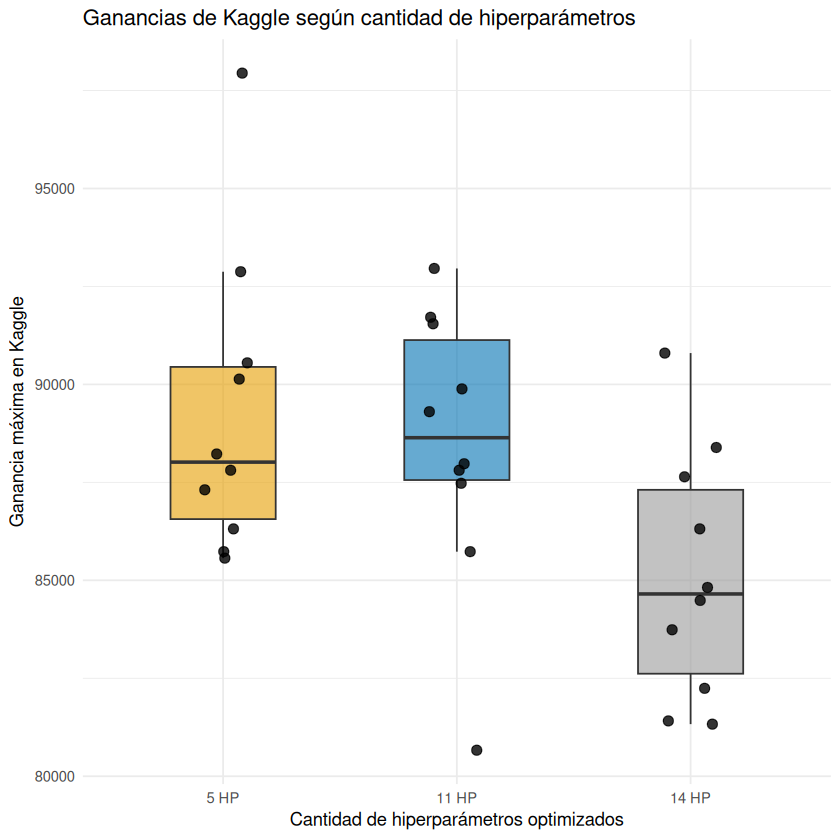

In [25]:
# ==========================================================
# 7a. BOXPLOT DE GANANCIAS SEGÚN CANTIDAD DE HP
# ==========================================================

ggplot(ganancias_largo, aes(x = HP, y = Ganancia, fill = HP)) +

  geom_boxplot(
    width = 0.45,
    alpha = 0.6,
    outlier.shape = NA
  ) +

  geom_jitter(
    width = 0.12,
    height = 0,
    size = 2.5,
    alpha = 0.8
  ) +

  scale_fill_manual(
    values = c(
      "5 HP" = "#E69F00",   # Naranja
      "11 HP" = "#0072B2",  # Azul
      "14 HP" = "#999999"   # Gris
    )
  ) +

  labs(
    title = "Ganancias de Kaggle según cantidad de hiperparámetros",
    x = "Cantidad de hiperparámetros optimizados",
    y = "Ganancia máxima en Kaggle"
  ) +

  theme_minimal() +
  theme(legend.position = "none")

ggsave(
  "boxplot_ganancias.png",
  plot = last_plot(),
  width = 10,
  height = 5.5,
  units = "in",
  dpi = 300,
  bg = "white"
)

**Resultado**:
Los experimentos A y B presentan una menor dispersión del 50% central de los resultados, con cierta asimetría hacia la derecha. El experimento B presenta una mediana ligeramente superior a la de A. Además, en A se observa un valor atípico superior, mientras que en B aparece uno inferior.

Por otro lado, el experimento C presenta la menor mediana y una mayor dispersión del 50% central de los resultados.

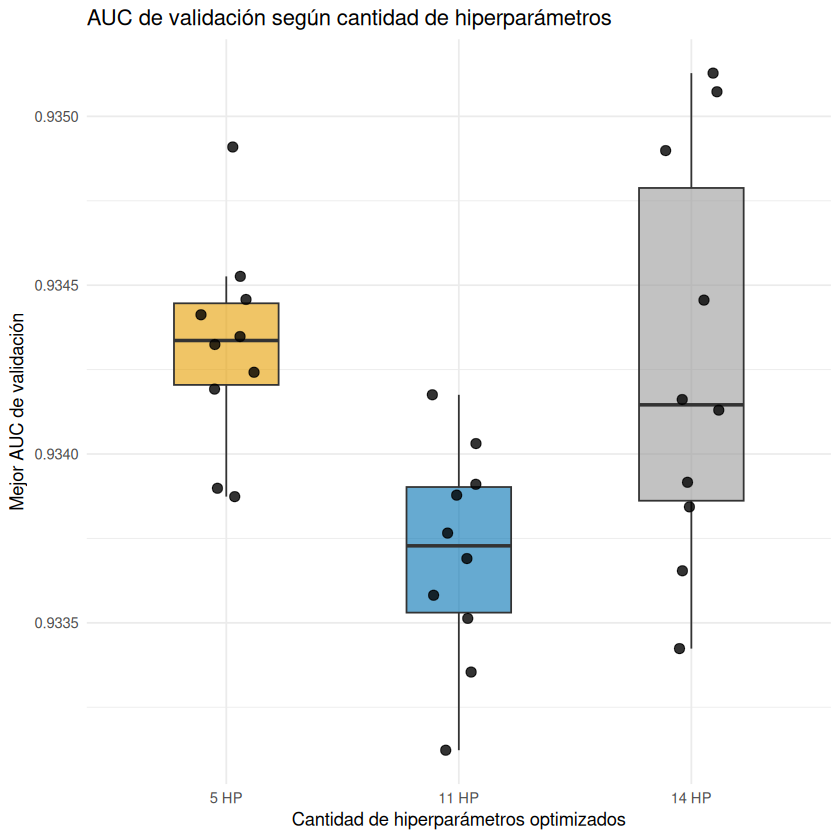

In [26]:
# ==========================================================
# BOXPLOT DE AUC SEGÚN CANTIDAD DE HP
# ==========================================================

ggplot(auc_largo, aes(x = HP, y = AUC, fill = HP)) +

  geom_boxplot(
    width = 0.45,
    alpha = 0.6,
    outlier.shape = NA
  ) +

  geom_jitter(
    width = 0.12,
    height = 0,
    size = 2.5,
    alpha = 0.8
  ) +

  scale_fill_manual(
    values = c(
      "5 HP" = "#E69F00",   # Naranja
      "11 HP" = "#0072B2",  # Azul
      "14 HP" = "#999999"   # Gris
    )
  ) +

  labs(
    title = "AUC de validación según cantidad de hiperparámetros",
    x = "Cantidad de hiperparámetros optimizados",
    y = "Mejor AUC de validación"
  ) +

  theme_minimal() +
  theme(legend.position = "none")

ggsave(
  "boxplot_auc.png",
  plot = last_plot(),
  width = 10,
  height = 5.5,
  units = "in",
  dpi = 300,
  bg = "white"
)

**Resultado:** El experimento A presenta la menor dispersión del 50% central de los valores de AUC, mientras que C presenta la mayor. Además, A tiene la mediana más alta, seguido por C y B. En general, se observa que los valores más bajos de AUC corresponden al experimento B.

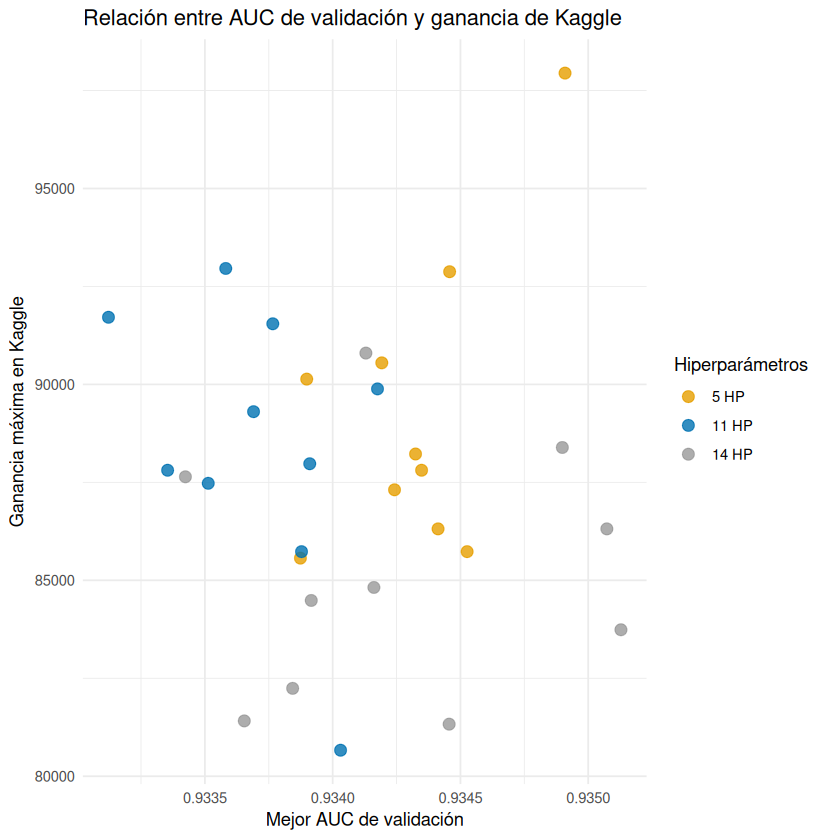

In [27]:
# ==========================================================
# SCATTERPLOT - AUC VS GANANCIA
# ==========================================================

ggplot(auc_ganancia,
       aes(x = AUC, y = Ganancia, color = HP)) +

  geom_point(
    size = 3,
    alpha = 0.8
  ) +

  scale_color_manual(
    values = c(
      "5 HP" = "#E69F00",
      "11 HP" = "#0072B2",
      "14 HP" = "#999999"
    )
  ) +

  labs(
    title = "Relación entre AUC de validación y ganancia de Kaggle",
    x = "Mejor AUC de validación",
    y = "Ganancia máxima en Kaggle",
    color = "Hiperparámetros"
  ) +

  theme_minimal()

ggsave(
  "scatter_AUC_ganancia.png",
  plot = last_plot(),
  width = 10,
  height = 5.5,
  units = "in",
  dpi = 300,
  bg = "white"
)

**Resultado**: no se observa un patron definido de asociación. Las ganancias varían sin un patrón claro respecto de la AUC.

In [28]:
# ==========================================================
# SCATTERPLOT: PREPARACIÓN DE DATOS DE ENVÍOS A KAGGLE
# ==========================================================

clientes_ganancia <- data.frame(
  HP = rep(c(5, 11, 14), each = 10),

  Clientes = c(
    ganancias$Clientes_A,
    ganancias$Clientes_B,
    ganancias$Clientes_C
  ),

  Ganancia = c(
    ganancias$A,
    ganancias$B,
    ganancias$C
  )
)

# Identifico los experimentos como categorías
clientes_ganancia$HP <- factor(
  clientes_ganancia$HP,
  levels = c(5, 11, 14),
  labels = c("5 HP", "11 HP", "14 HP")
)

head(clientes_ganancia)

,HP,Clientes,Ganancia
,<fct>,<dbl>,<dbl>
1,5 HP,2000,85732
2,5 HP,1900,90135
3,5 HP,1800,87310
4,5 HP,1600,86313
5,5 HP,1500,90550
6,5 HP,2000,87809


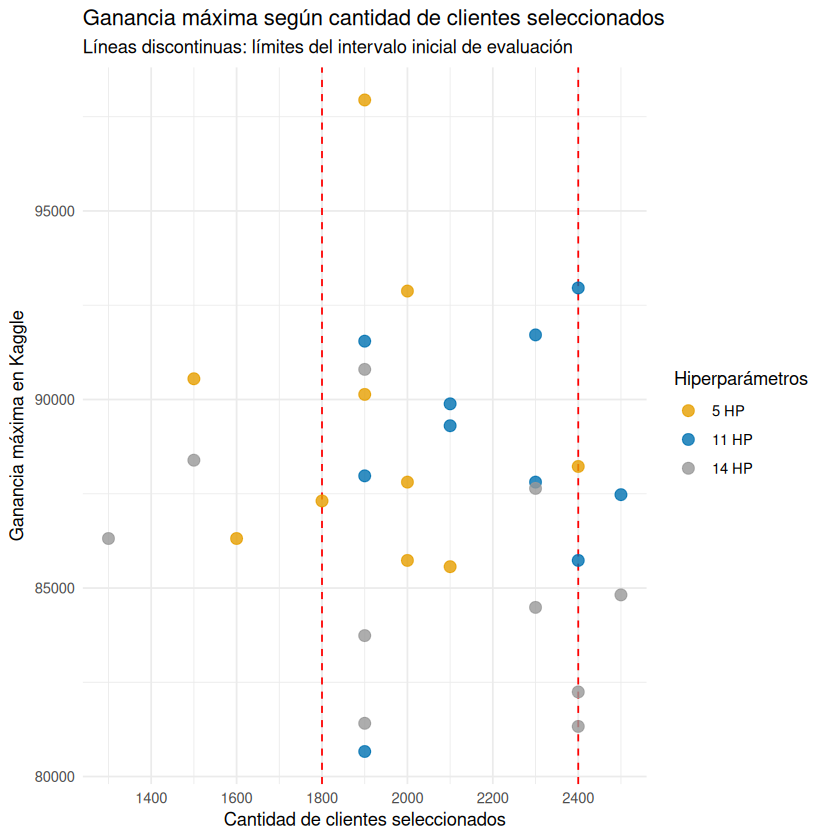

In [29]:
# ==========================================================
# SCATTERPLOT: CLIENTES SELECCIONADOS VS GANANCIA
# ==========================================================

ggplot(clientes_ganancia,
       aes(x = Clientes, y = Ganancia, color = HP)) +

  # Límites del intervalo original de Kaggle
  geom_vline(
    xintercept = c(1800, 2400),
    linetype = "dashed",
    color = "red"
  ) +

  # Puntos individuales
  geom_point(
    size = 3,
    alpha = 0.8
  ) +

  scale_color_manual(
    values = c(
      "5 HP" = "#E69F00",
      "11 HP" = "#0072B2",
      "14 HP" = "#999999"
    )
  ) +

  scale_x_continuous(
    breaks = seq(1200, 2800, by = 200)
  ) +

  labs(
    title = "Ganancia máxima según cantidad de clientes seleccionados",
    subtitle = "Líneas discontinuas: límites del intervalo inicial de evaluación",
    x = "Cantidad de clientes seleccionados",
    y = "Ganancia máxima en Kaggle",
    color = "Hiperparámetros"
  ) +

  theme_minimal()

ggsave(
  "scatter_clientes_ganancia.png",
  plot = last_plot(),
  width = 10,
  height = 5.5,
  units = "in",
  dpi = 300,
  bg = "white"
)

**Resultado**: La mayoría de las ganancias máximas se obtuvieron al seleccionar entre 1800 y 2400 clientes, dentro del rango inicial de evaluación. Sin embargo, en algunas semillas fue necesario ampliar este rango para encontrar ganancias mayores. Además, se observó que, para una misma cantidad de clientes seleccionados, las ganancias obtenidas podían ser diferentes.

###Paso 8. Comparación estadística mediante Test de  Wilcoxon

In [30]:
# ==========================================================
# 8. TEST DE WILCOXON APAREADO
# ==========================================================

# Verifico si están completas las 10 ganancias
# de cada experimento

if (anyNA(ganancias[, c("A", "B", "C")])) {

  cat("Faltan resultados para realizar Wilcoxon.\n")
  cat("Cantidad de datos faltantes por experimento:\n")

  print(colSums(is.na(ganancias[, c("A", "B", "C")])))

} else {

  # Comparaciones entre experimentos

  AB <- wilcox.test(ganancias$A, ganancias$B,
                    paired = TRUE, exact = FALSE)

  AC <- wilcox.test(ganancias$A, ganancias$C,
                    paired = TRUE, exact = FALSE)

  BC <- wilcox.test(ganancias$B, ganancias$C,
                    paired = TRUE, exact = FALSE)

  # Tabla de resultados

  resultados_wilcoxon <- data.frame(
    Comparacion = c("A vs B", "A vs C", "B vs C"),
    p_valor = c(AB$p.value, AC$p.value, BC$p.value)
  )

  # Corrección por comparaciones múltiples
  resultados_wilcoxon$p_ajustado <- p.adjust(
    resultados_wilcoxon$p_valor,
    method = "holm"
  )

  print(resultados_wilcoxon)
}

  Comparacion     p_valor p_ajustado
1      A vs B 0.905695442 0.90569544
2      A vs C 0.102917539 0.20583508
3      B vs C 0.008045237 0.02413571


Al comparar las ganancias de los tres experimentos mediante el test de Wilcoxon apareado, con la corrección de Holm, no encontramos diferencias estadísticamente significativas entre A y B ni entre A y C. En cambio, sí se encontró una diferencia significativa entre B y C (p ajustado = 0,0241).

Por lo tanto, los resultados obtenidos no permiten sostener nuestra hipótesis de que optimizar simultáneamente una mayor cantidad de hiperparámetros aumenta la ganancia.

Al observar la estadística descriptiva, los experimentos A y B presentaron resultados bastante similares. Si bien B obtuvo una mediana ligeramente mayor y una menor dispersión, A presentó una ganancia promedio más alta, aunque influida por un valor particularmente elevado.

Teniendo en cuenta estos resultados y que A utiliza solamente cinco hiperparámetros, podríamos optar por continuar trabajando con este experimento, ya que no encontramos evidencia de que optimizar los seis hiperparámetros adicionales de B haya mejorado significativamente las ganancias.

###Paso 9. Evaluación de los rangos de búsqueda y propuestas de optimización futura

Al analizar los valores obtenidos por BO en el experimento A, observamos que algunos hiperparámetros quedaron próximos a los límites de búsqueda, principalmente `learning_rate` y `num_leaves`. Por este motivo, sería conveniente evaluar una ampliación de estos rangos para comprobar si se pueden obtener mejores ganancias. También habría que considerar ampliar `num_iterations`, ya que al disminuir `learning_rate` podría ser necesario aumentar la cantidad de iteraciones.

Al analizar los valores obtenidos por BO, observamos que `learning_rate` 
fue el hiperparámetro que presentó una mayor concentración de resultados 
próximos al límite inferior en los tres experimentos (70% en A y 60% en B y C).
En el experimento A, también se observó que el 70% de los valores de `num_leaves` 
quedaron próximos al límite superior. En B y C, `max_depth` presentó un 40% de 
valores próximos a los límites, mientras que `min_data_in_leaf` alcanzó el 50% en B
y el 30% en C.Además, `bagging_fraction` presentó un 40% de valores próximos a los 
límites tanto en B como en C, aunque la concentración hacia el límite superior 
fue mayor en C. Algo similar ocurrió con `feature_fraction_bynode` en C, 
donde el 50% de los valores quedaron próximos a los límites, principalmente 
al superior.